# Testing

In [1]:
import sys, json
sys.path.insert(0, "..")                      # repo root, so `utils` imports work
from utils.prompt_utils import AmbigousARCDataset

ds = AmbigousARCDataset(task="generation", items_data="../data/items/items_updated.json")
print(ds.size, ds.n_items)                    # expect 300, 300
print(ds.x[0])

exp = {i["main_id"]: i for i in json.load(open("../data/items/items_updated_exp.json"))
       if i["mirror"] == "1"}
mism = [iid for iid, y in zip(ds.item_ids, ds.y)
        if y[0] != exp[iid.split("_")[0]]["D_Matrix"]]
print(len(mism), "D_Matrix mismatches")       # want 0

300 300
EXAMPLE TASK:

Input 1: [7 7 0] [3 3 0] [7 3 7]
Output 1: [0 0 0] [3 3 0] [7 3 0]
Input 2: [0 7 0] [0 3 3] [7 3 7]
Output 2:

Answer: [0 0 0] [0 3 3] [0 3 7]

TEST TASK:

Input 1: [2 2 2 2 0] [1 1 1 0 0] [1 1 1 1 1] [2 0 0 0 0] [2 2 0 0 0]
Output 1: [2 0 0 0 0] [2 2 0 0 0] [1 1 1 0 0] [2 2 2 2 0] [1 1 1 1 1]
Input 2: [3 3 3 0 0] [3 3 3 3 3] [6 0 0 0 0] [3 3 0 0 0] [6 6 6 6 0]
Output 2:

Answer: 
0 D_Matrix mismatches


In [2]:
out = {"item_ids": ds.item_ids, "prompts": ds.x, "answers": ds.y,  # answers = [D_Matrix, D_Concept]
       "examples": ds.example_items, "config": ds.get_config()}
json.dump(out, open("prompts.json", "w"), indent=2)

In [3]:
import os
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv("keys.env")
client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.environ["OPENROUTER_API_KEY"])

SYSTEM = "You are a helpful assistant that solves analogy making puzzles. Only give the answer, no other words or text."

r = client.chat.completions.create(
    model="meta-llama/llama-3.3-70b-instruct",
    messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": out["prompts"][0]}],
    temperature=0, max_tokens=100,
)
print(repr(r.choices[0].message.content))
print(r.choices[0].finish_reason, r.usage, getattr(r, "provider", None))
print("expected:", out["answers"][0])

'[6 0 0 0 0] [6 6 6 6 0] [3 3 3 0 0] [3 3 3 3 3] [6 6 6 0 0]'
stop CompletionUsage(completion_tokens=56, prompt_tokens=348, total_tokens=404, completion_tokens_details=CompletionTokensDetails(accepted_prediction_tokens=None, audio_tokens=0, reasoning_tokens=0, rejected_prediction_tokens=None, text_tokens=None, image_tokens=0), prompt_tokens_details=PromptTokensDetails(audio_tokens=0, cache_write_tokens=0, cached_tokens=16, image_tokens=None, text_tokens=None, video_tokens=0), cost=9.712e-05, is_byok=False, cost_details={'upstream_inference_cost': 9.712e-05, 'upstream_inference_prompt_cost': 6.8e-05, 'upstream_inference_completions_cost': 2.912e-05}) AkashML
expected: ['3000022033600003222011111', '6000033000333006666033333']


In [4]:
import re, time, json
import pandas as pd
from utils.eval import filter_response, delimit_response   # collaborator's parser, for comparison

# ---- items: dims and A/B/C for scoring ----
items = {i["id"]: i for i in json.load(open("../data/items/items_updated.json"))}

def parse_grid(text, dim):
    """Return the response as a dim*dim digit string, or None if unparseable."""
    if text is None:
        return None
    rows = ["".join(re.findall(r"\d", r)) for r in re.findall(r"\[([^\[\]]*)\]", text)]
    rows = [r for r in rows if r]
    for start in range(len(rows) - dim + 1):            # first `dim` consecutive rows of length `dim`
        block = rows[start:start + dim]
        if all(len(r) == dim for r in block):
            return "".join(block)
    digits = "".join(re.findall(r"\d", text))           # fallback: no usable brackets
    return digits if len(digits) == dim * dim else None

def score(grid, item, d_matrix, d_concept):
    if grid is None:                      return "unparseable"
    if grid == d_concept:                 return "concept"
    if grid == d_matrix:                  return "matrix"
    if grid in (item["A"], item["B"], item["C"]): return "duplicate"   # collaborator's definition
    return "other"

def collab_parse(text):
    f = filter_response(text) if text else None
    return delimit_response(f) if f else None

# ---- run ----
MODEL = "meta-llama/llama-3.3-70b-instruct"
rows = []
for iid, prompt, (d_matrix, d_concept) in list(zip(out["item_ids"], out["prompts"], out["answers"]))[:10]:
    item = items[iid.split("_")[0]]
    t0 = time.time()
    r = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}],
        temperature=0, max_tokens=100,
        extra_body={"provider": {"order": ["together"], "allow_fallbacks": False}},
    )
    text = r.choices[0].message.content
    g_new, g_old = parse_grid(text, item["xdim"]), collab_parse(text)
    rows.append({
        "item_id": iid, "dim": item["xdim"], "concept": item["concept"],
        "raw": text, "finish": r.choices[0].finish_reason,
        "provider": getattr(r, "provider", None), "rt": round(time.time() - t0, 2),
        "parsed_new": g_new, "parsed_old": g_old,
        "score_new": score(g_new, item, d_matrix, d_concept),
        "score_old": score(g_old, item, d_matrix, d_concept),
        "prompt_tokens": r.usage.prompt_tokens,
        "completion_tokens": r.usage.completion_tokens,
        "cost": getattr(r.usage, "cost", None),
    })

df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", None)

In [5]:
df[["item_id", "dim", "raw", "finish", "provider", "score_new", "score_old", "cost"]]

,item_id,dim,raw,finish,provider,score_new,score_old,cost
0,02ue5B_1,5,[6 0 0 0 0] [6 6 6 6 0] [3 3 3 0 0] [3 3 3 3 3] [6 0 0 0 0],stop,Together,other,other,0.000399
1,02wXdR_1,3,[2 0 2] [0 2 2] [2 2 2],stop,Together,other,other,0.000399
2,0Zgi5T_1,3,[3 3 3] [0 2 2] [0 0 0],stop,Together,other,other,0.000258
3,15a8kn_1,5,[0 3 0 0 1] [0 1 0 0 1] [0 0 0 0 1] [1 1 0 0 0] [0 0 0 3 3],stop,Together,other,other,0.000399
4,1Gjg7C_1,3,[3 3 3] [3 3 3] [3 3 3],stop,Together,concept,concept,0.000399
5,28LwJ6_1,3,[5 5 5] [1 0 0] [7 7 0],stop,Together,other,other,0.000399
6,2hmBPx_1,5,[0 0 2 0 0] [0 3 3 3 0] [0 0 0 0 0] [0 3 3 3 0] [0 0 2 0 0],stop,Together,other,other,0.000399
7,2sSXgS_1,3,[0 0 0] [3 3 3] [0 0 0],stop,Together,other,other,0.000258
8,2ZfhY0_1,5,[2 2 2 2 2] [2 0 2 2 2] [2 2 2 2 2] [2 2 2 0 2] [2 2 2 2 2],stop,Together,other,other,0.000541
9,3IxIxw_1,5,[0 0 0 0 2] [0 0 0 0 2] [0 0 0 0 2] [4 4 4 4 2] [0 0 0 0 2],stop,Together,concept,concept,0.000541


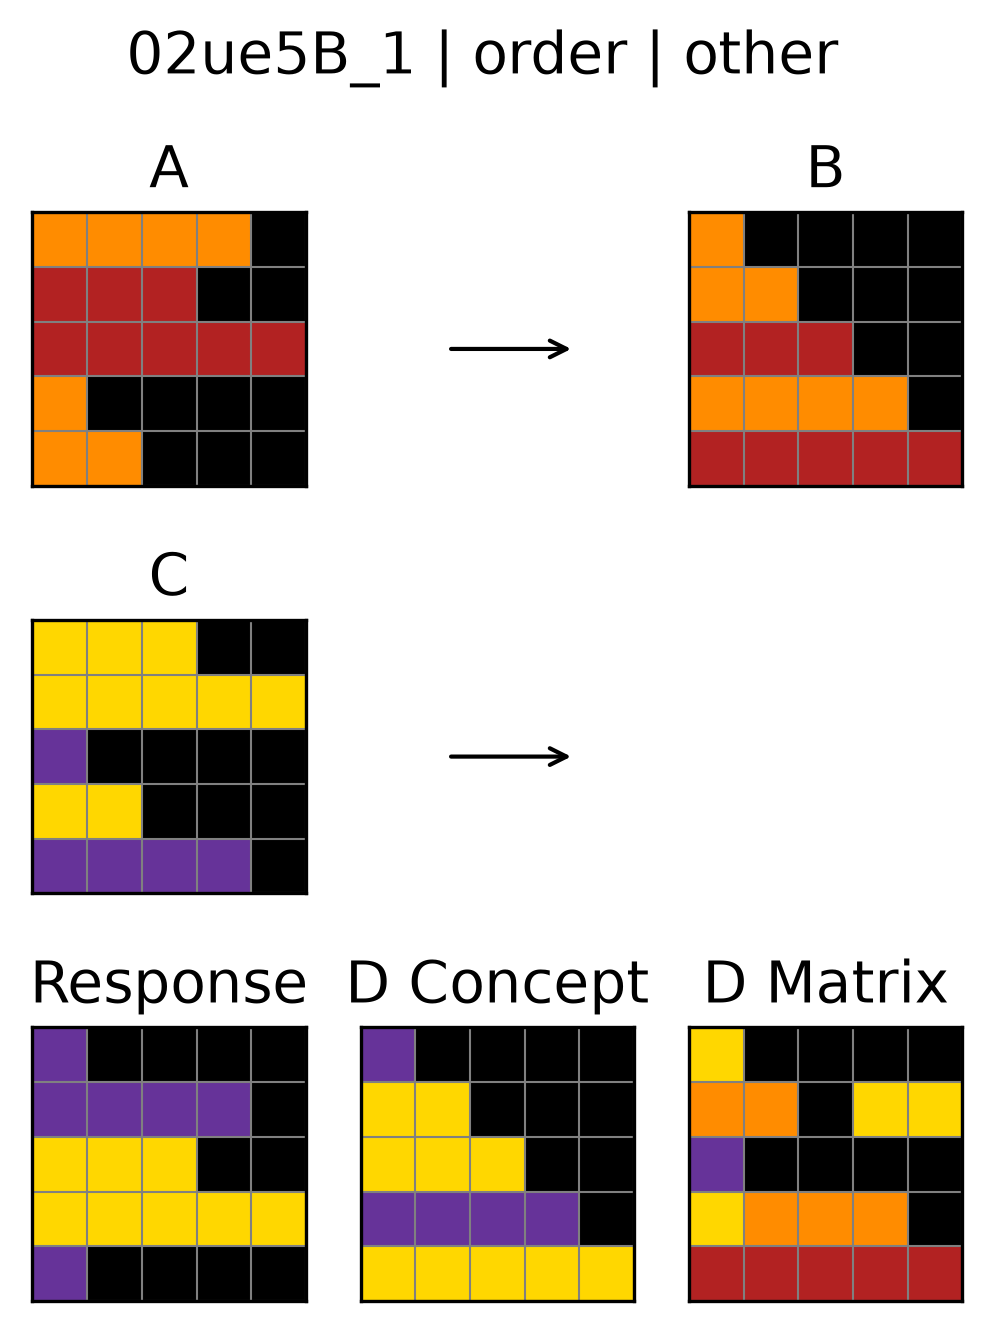

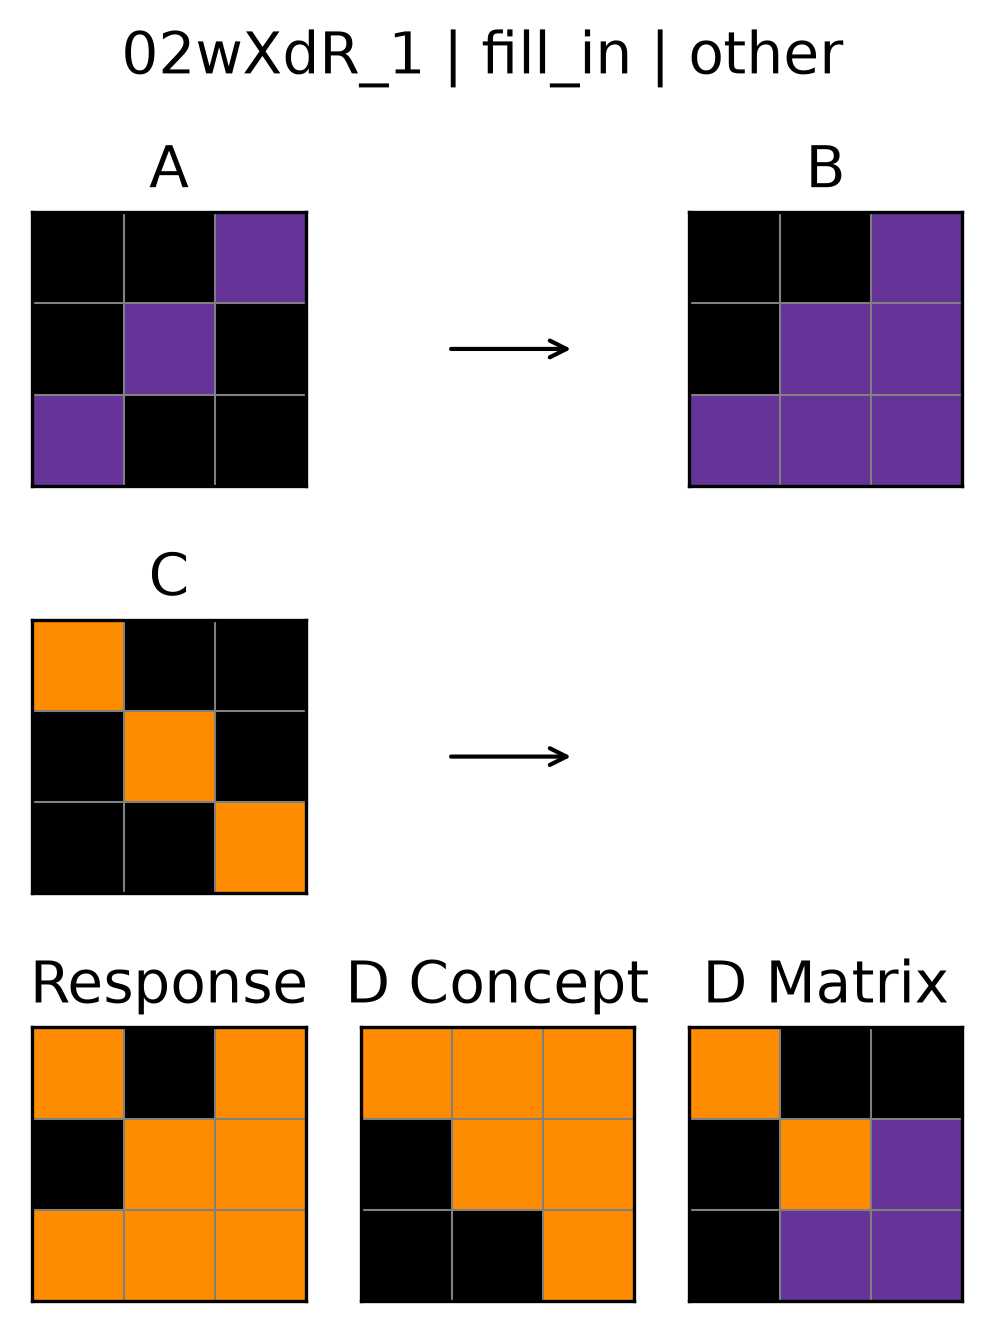

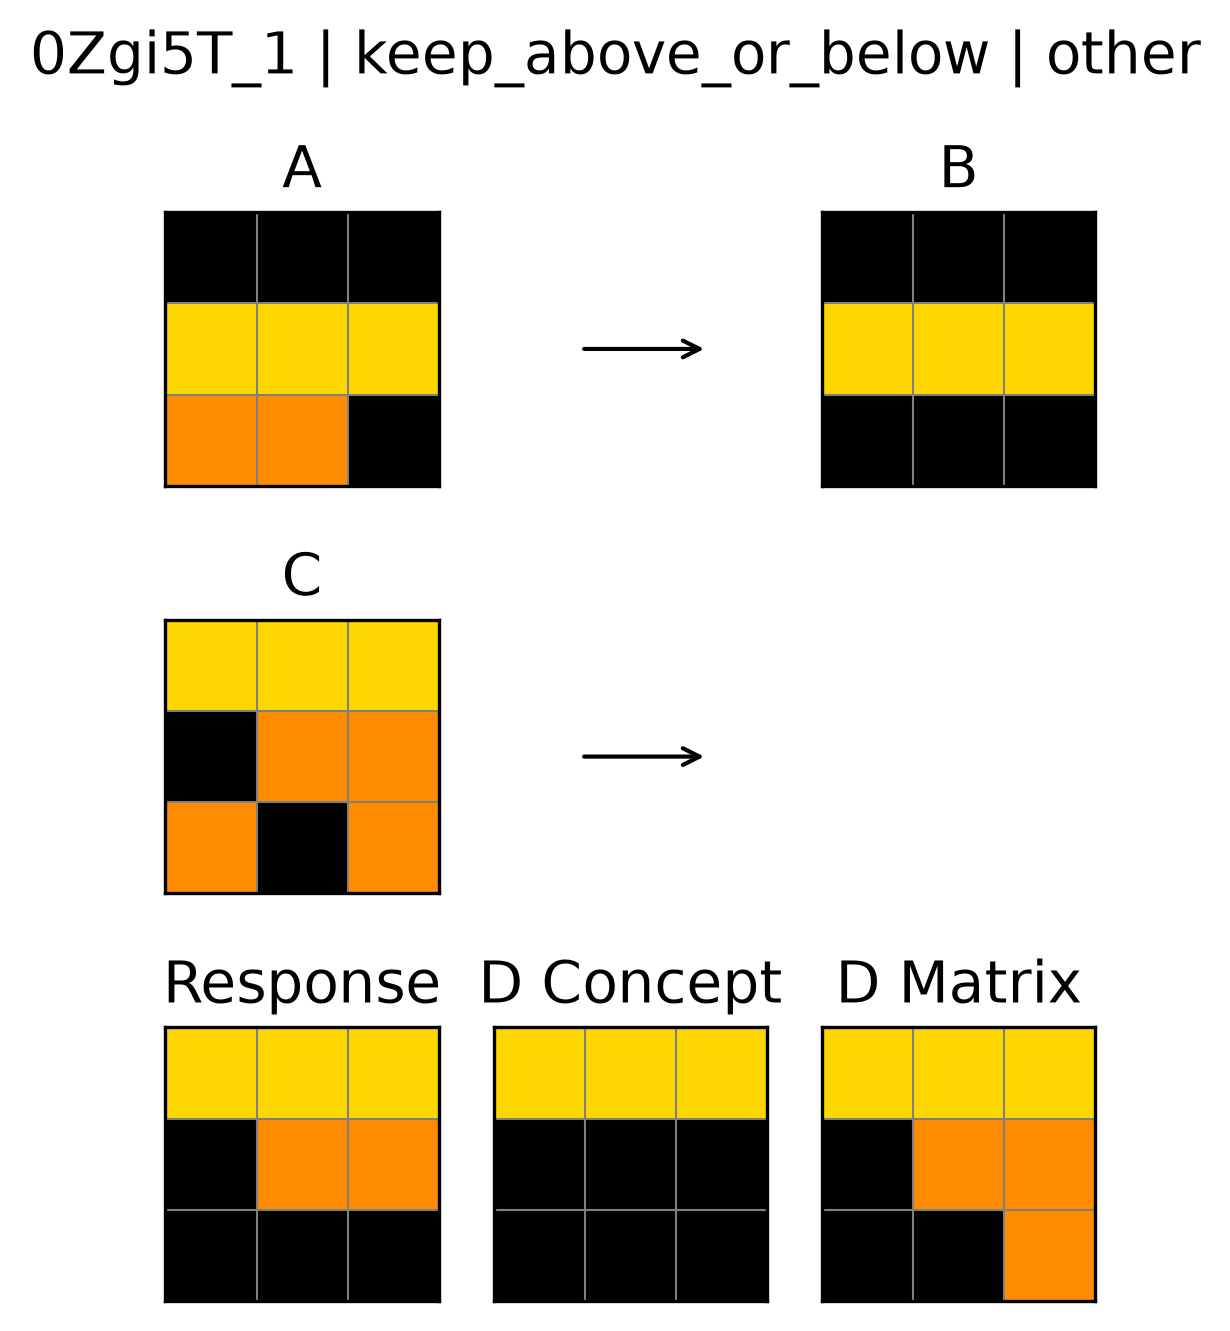

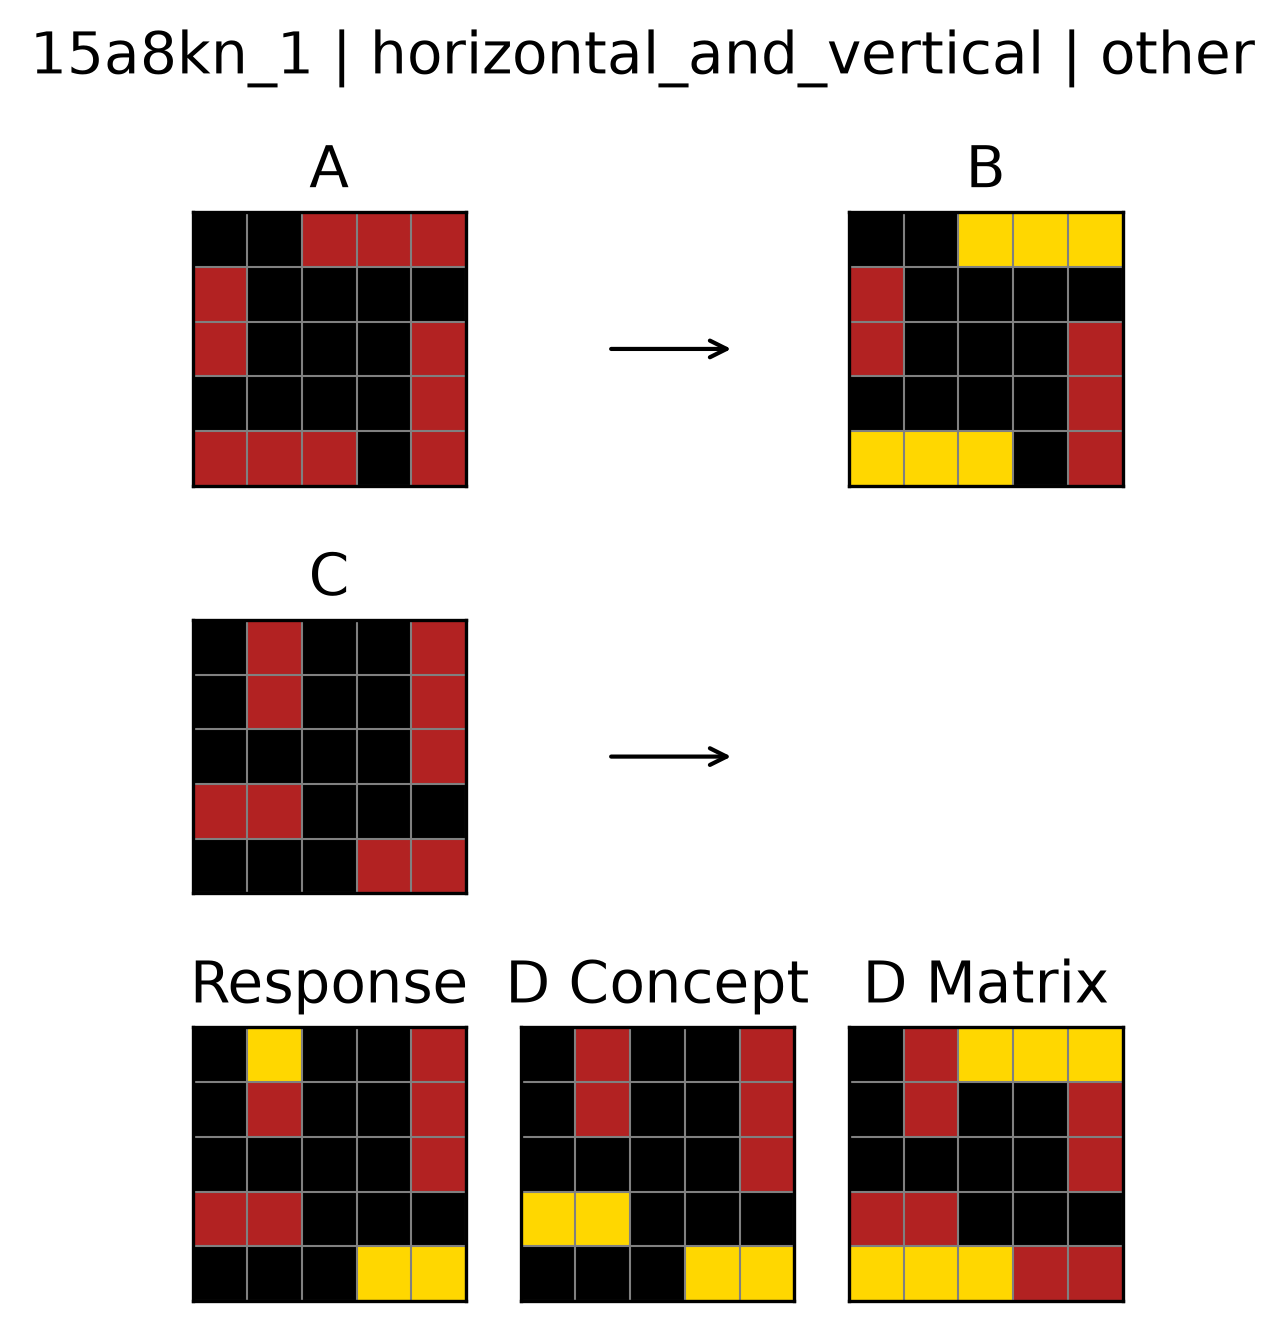

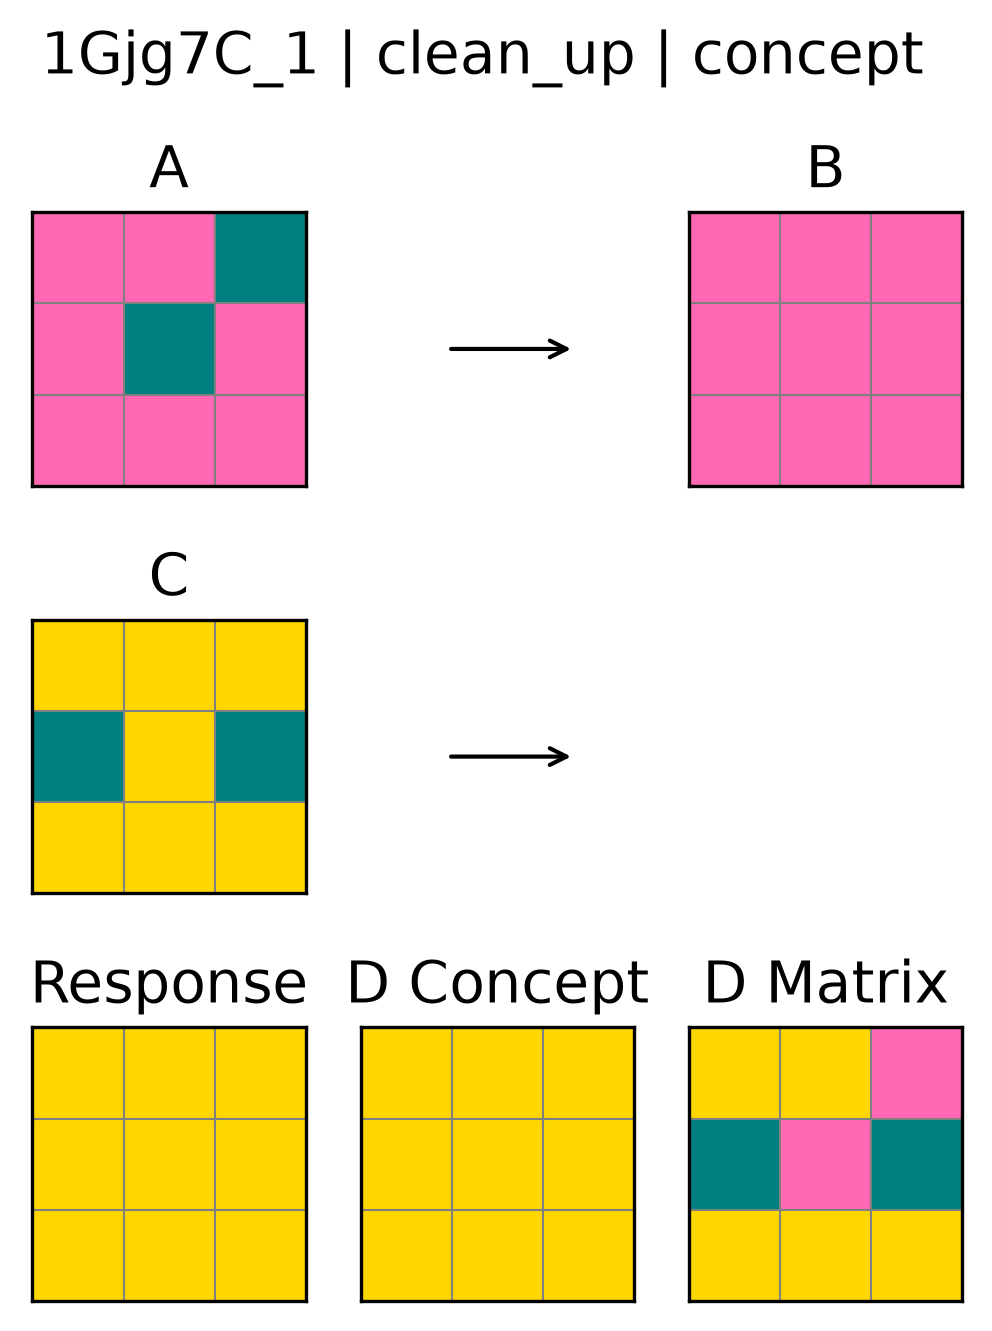

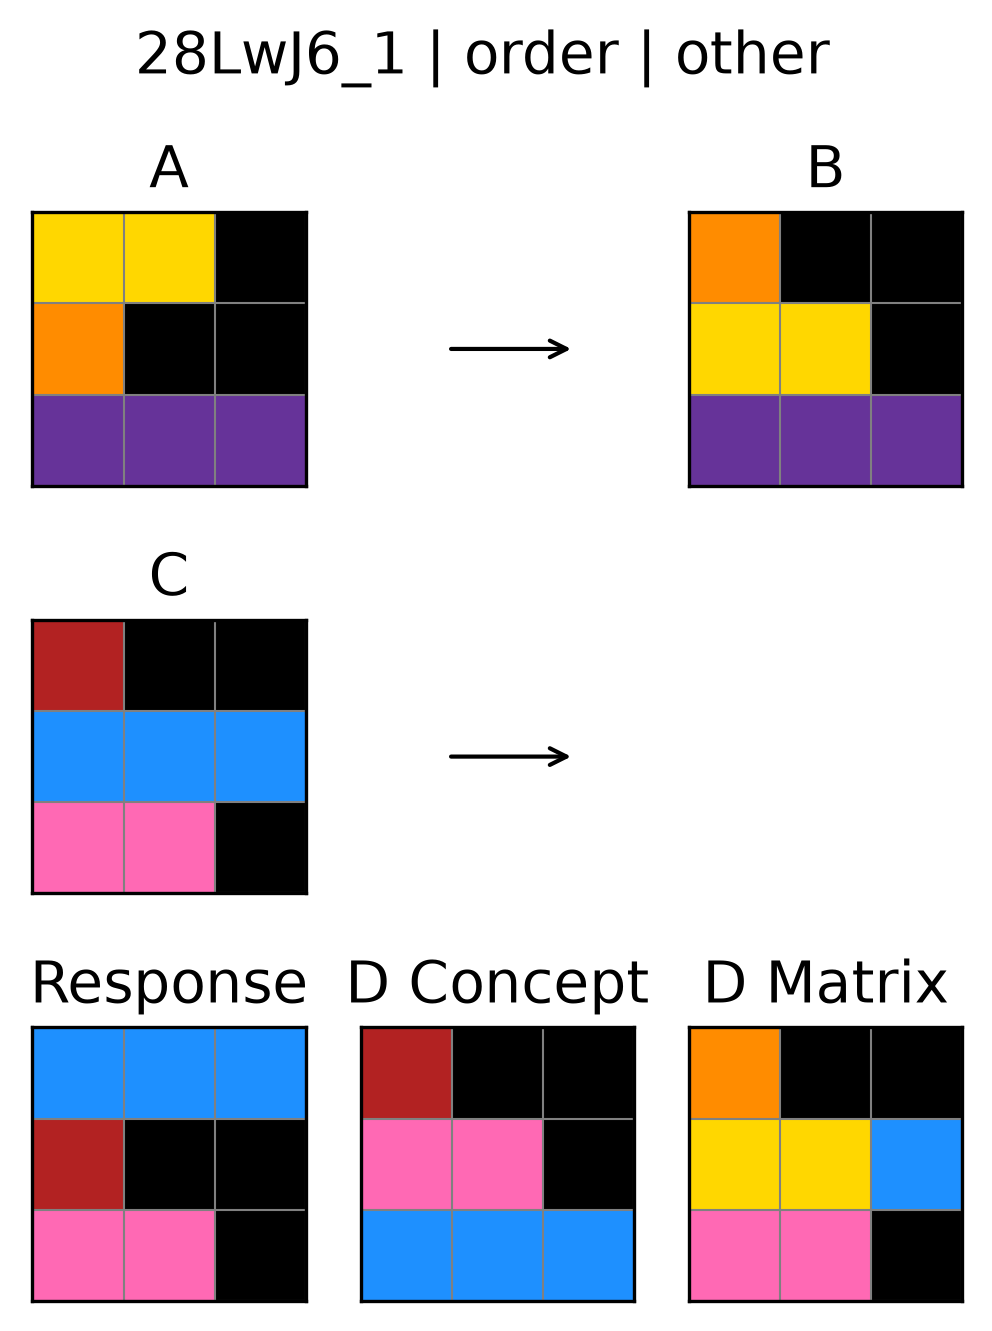

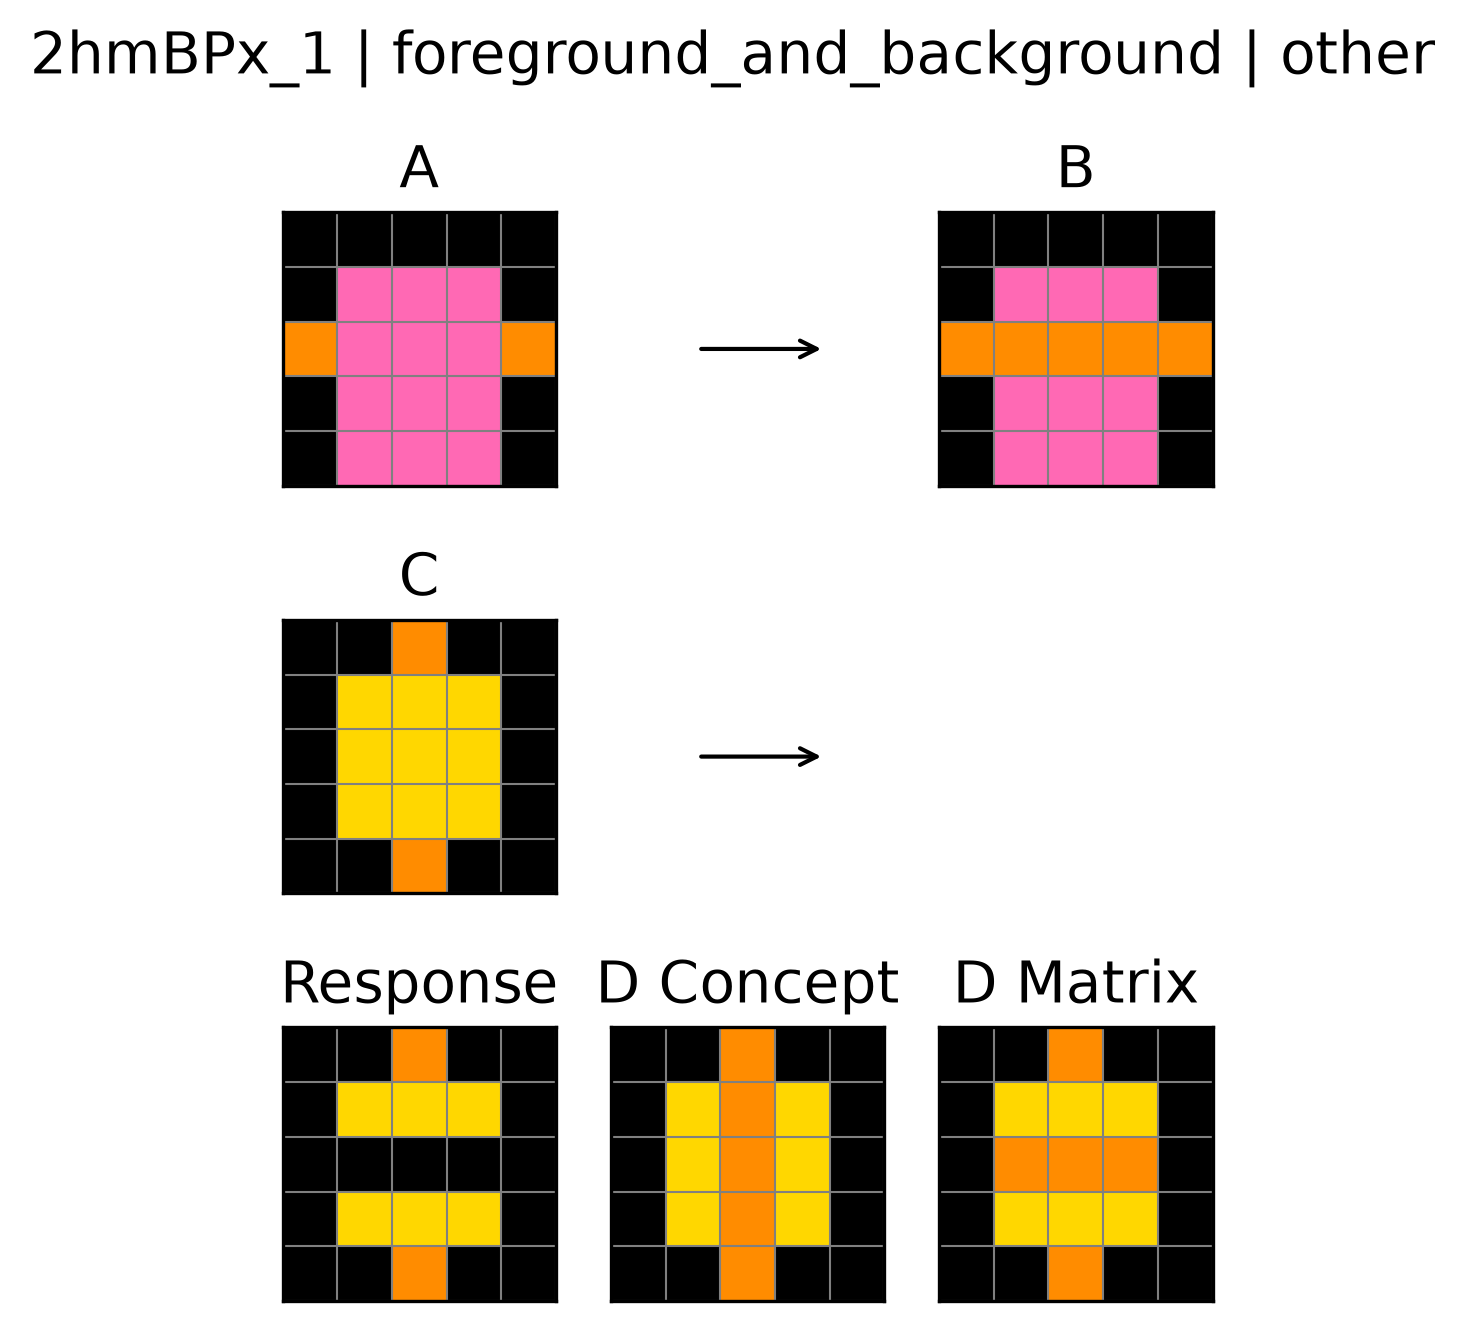

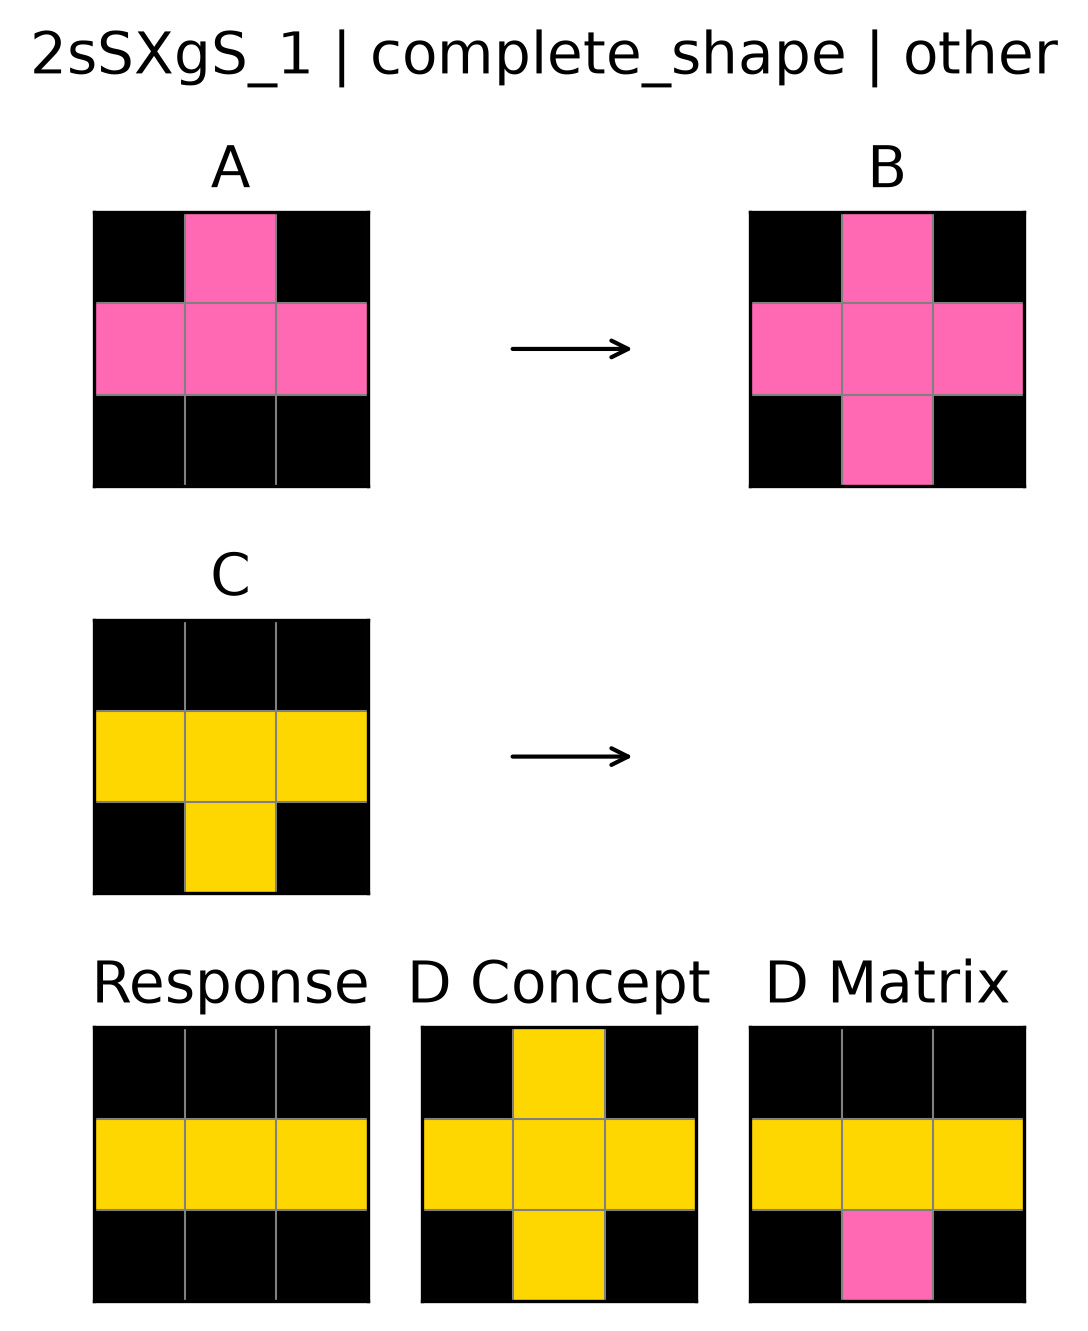

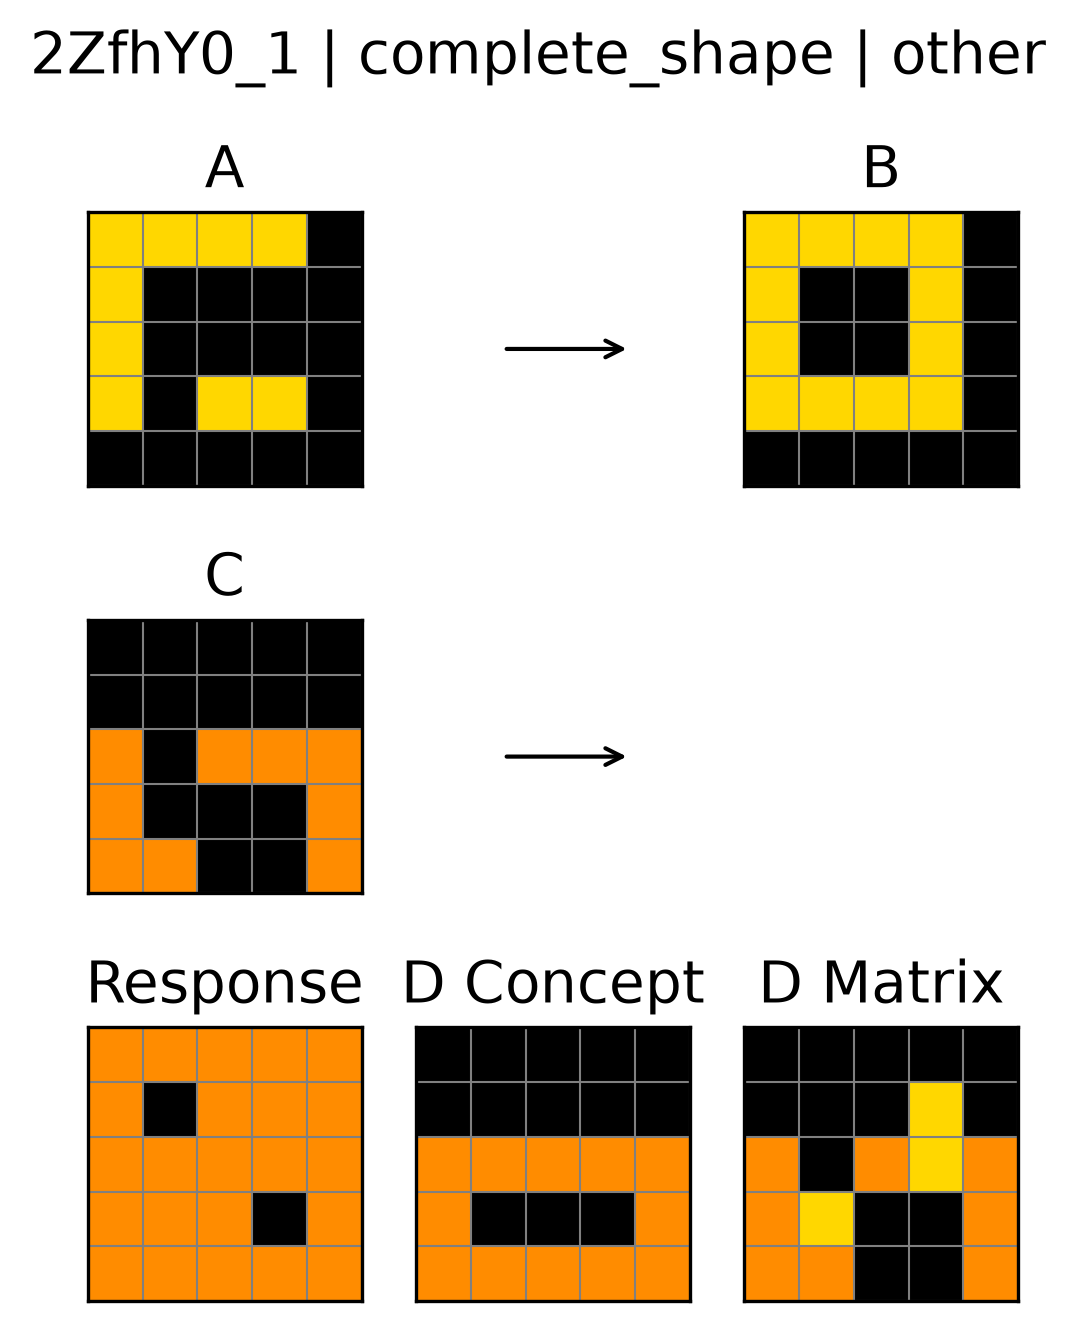

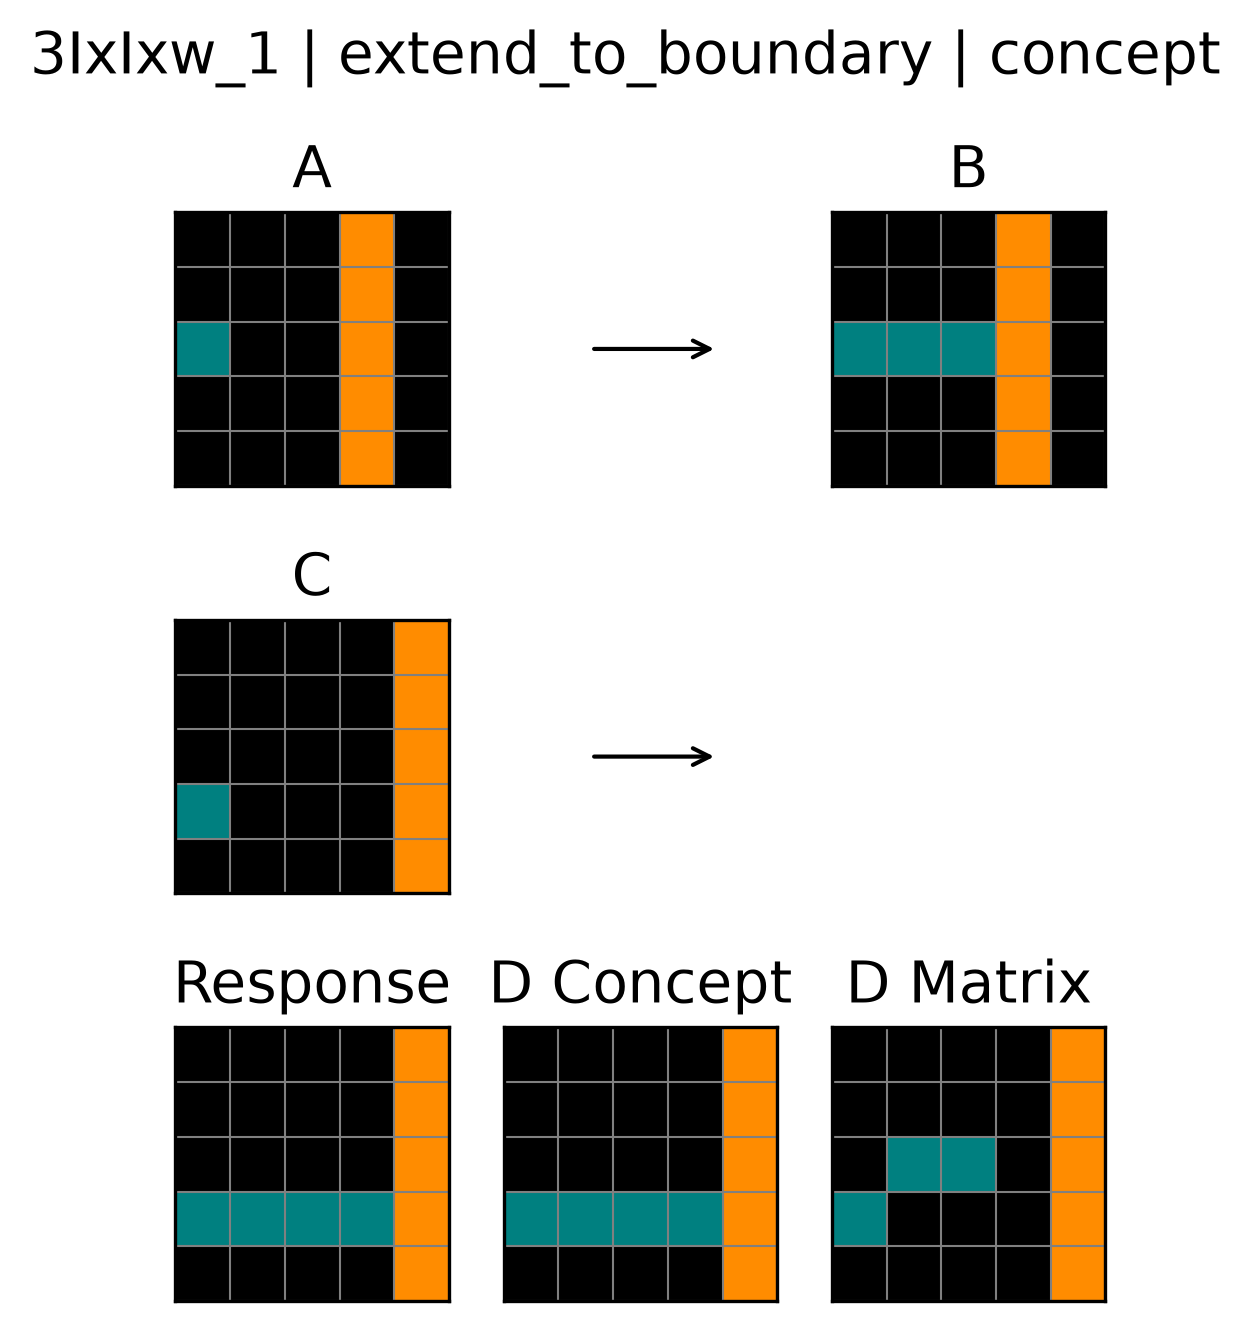

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from utils.plot_utils import plot_item
from utils.prompt_utils import convert_to_array

def show_response(row):
    item = items[row["item_id"].split("_")[0]]
    d = row["dim"]
    d_matrix, d_concept = out["answers"][out["item_ids"].index(row["item_id"])]
    if row["parsed_new"] is None:
        resp, resp_label = np.zeros((d, d), dtype=int), "Unparseable"
        print(f"{row['item_id']} raw: {row['raw']!r}")
    else:
        resp, resp_label = convert_to_array(row["parsed_new"], d), "Response"
    arrs = [convert_to_array(item[k], d) for k in ["A", "B", "C"]] + \
           [resp, convert_to_array(d_concept, d), convert_to_array(d_matrix, d)]
    plot_item(arrays=arrs,
              title=f"{row['item_id']} | {row['concept']} | {row['score_new']}",
              labels=["A", "B", "C", resp_label, "D Concept", "D Matrix"])
    plt.show()

for _, row in df.iterrows():
    show_response(row)

# Plotting

In [3]:
import pandas as pd

raw = pd.read_json("results/raw/pilot.jsonl", lines=True)
r1 = raw[(raw.model == "openai/o4-mini") & raw.error.isna()]

cols = ["item_id", "reasoning_tokens", "completion_tokens", "cost", "rt", "finish_reason"]
print(r1[cols])
r1[["reasoning_tokens", "completion_tokens", "cost", "rt"]].agg(["mean", "min", "max", "sum"])

     item_id  reasoning_tokens  completion_tokens  cost     rt finish_reason
50  02ue5B_1            1088.0             1184.0   0.0  12.41          stop
51  15a8kn_1            1792.0             1901.0   0.0  17.63          stop
52  02wXdR_1            3008.0             3039.0   0.0  32.48          stop
53  1Gjg7C_1            2368.0             2404.0   0.0  23.29          stop
54  0Zgi5T_1            9600.0             9647.0   0.0  75.25          stop


,reasoning_tokens,completion_tokens,cost,rt
mean,3571.2,3635.0,0.0,32.212
min,1088.0,1184.0,0.0,12.410
max,9600.0,9647.0,0.0,75.250
sum,17856.0,18175.0,0.0,161.060


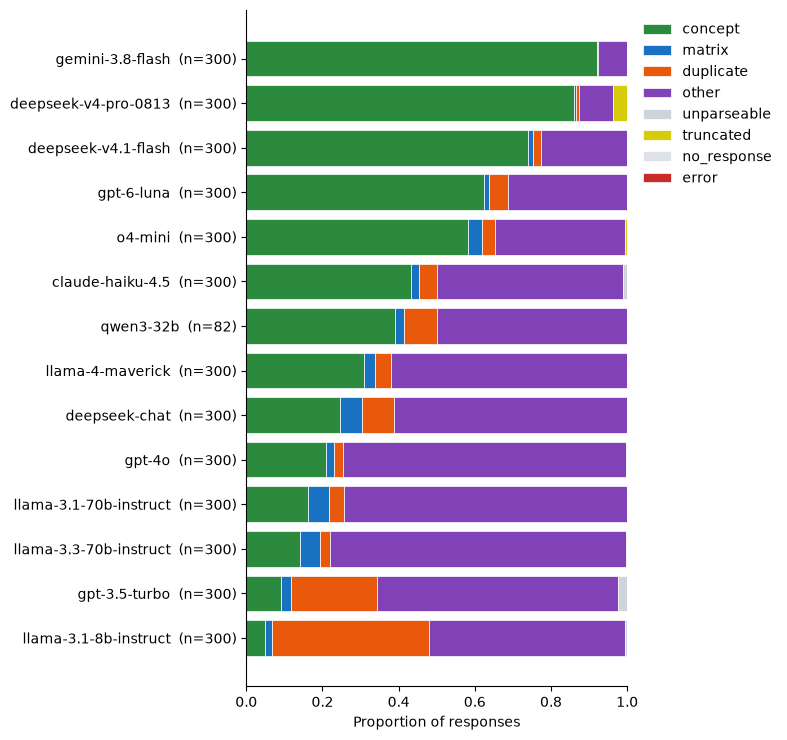

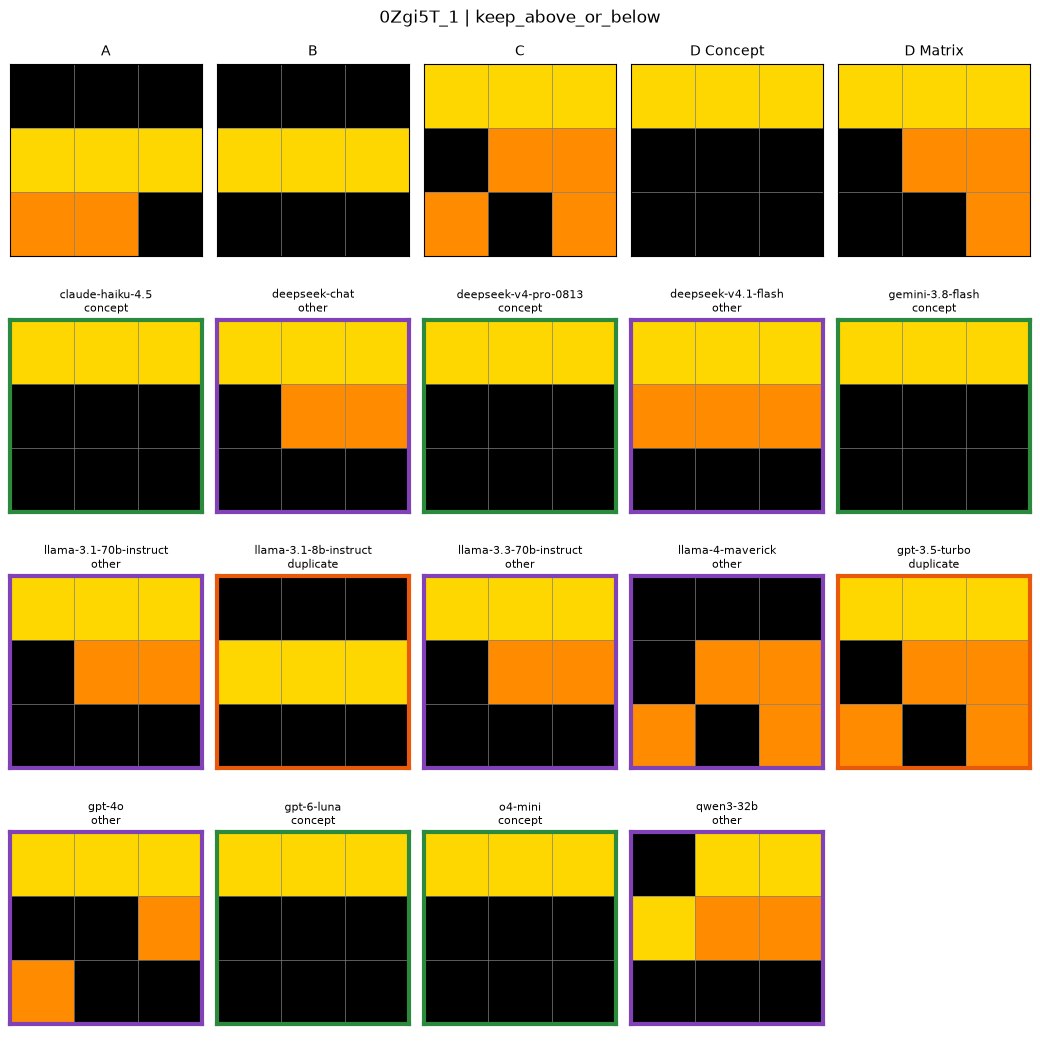

In [4]:
from score import score_run
from pilot_plots import plot_performance, plot_item_across_models, plot_responses

scored = score_run("results/raw/combined_prelim300.jsonl")

plot_performance(scored)                                  # stacked bars per model
plot_item_across_models(scored, "0Zgi5T_1")               # one item, every model's answer
# plot_responses(scored, model="openai/o4-mini", n=3)

In [26]:
27 / 300 * 100

9.0

In [14]:
import glob, httpx, pandas as pd

# list prices per token from OpenRouter (no credits needed)
prices = {m["id"]: (float(m["pricing"]["prompt"]), float(m["pricing"]["completion"]))
          for m in httpx.get("https://openrouter.ai/api/v1/models").json()["data"]}

raw = pd.concat([pd.read_json(f, lines=True) for f in glob.glob("results/raw/prelim_pilot*.jsonl")])
ok = raw[raw.error.isna()].copy()
ok["model_id"] = ok["model_id"].fillna(ok["model"]) if "model_id" in ok else ok["model"]

ok["list_cost"] = (ok.prompt_tokens * ok.model_id.map(lambda m: prices.get(m, (float("nan"),) * 2)[0])
                 + ok.completion_tokens * ok.model_id.map(lambda m: prices.get(m, (float("nan"),) * 2)[1]))

N_ITEMS, CONCURRENCY = 300, 8
summary = ok.groupby("model").agg(
    n=("item_id", "size"),
    rt_s=("rt", "mean"),
    completion_tok=("completion_tokens", "mean"),
    reported_cost=("cost", "mean"),
    list_cost=("list_cost", "mean"),
    truncated=("finish_reason", lambda s: (s == "length").sum()),
)
summary["est_300_$"] = summary.list_cost * N_ITEMS
summary["est_300_h"] = summary.rt_s * N_ITEMS / CONCURRENCY / 3600
summary = summary.sort_values("est_300_$", ascending=False)

print(summary.round(4))
print(f"\nTotal projected: ${summary['est_300_$'].sum():.2f}")

ValueError: No objects to concatenate

# Testing

In [5]:
import os, json, requests
from dotenv import load_dotenv
load_dotenv("keys.env")

resp = requests.get(
    "https://openrouter.ai/api/v1/models/google/gemini-3.8-flash/endpoints",
    headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"},
).json()
print(json.dumps(resp, indent=2))

{
  "data": {
    "id": "google/gemini-3.8-flash",
    "name": "Google: Gemini 3.8 Flash",
    "created": 1788362056,
    "description": "Gemini 3.8 Flash is Google's most intelligent Flash model with significant gains from 3.7 Flash across software engineering, agentic tasks, and multi-step reasoning.",
    "architecture": {
      "tokenizer": "Gemini",
      "instruct_type": null,
      "modality": "text+image+file+audio+video->text",
      "input_modalities": [
        "text",
        "image",
        "video",
        "file",
        "audio"
      ],
      "output_modalities": [
        "text"
      ]
    },
    "endpoints": [
      {
        "name": "Google AI Studio | google/gemini-3.8-flash-20260902",
        "model_id": "google/gemini-3.8-flash",
        "model_name": "Google: Gemini 3.8 Flash",
        "context_length": 1048576,
        "pricing": {
          "prompt": "0.000000375",
          "completion": "0.000001875",
          "image": "0.000000375",
          "audio": "0.

In [6]:
import httpx
httpx.get("https://openrouter.ai/api/v1/key",
          headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"}).json()

{'data': {'label': 'sk-or-v1-48d...77e',
  'is_management_key': False,
  'is_provisioning_key': False,
  'limit': 1000,
  'limit_reset': None,
  'limit_remaining': 999.626680568,
  'include_byok_in_limit': False,
  'usage': 0.373319432,
  'usage_daily': 0.373319432,
  'usage_weekly': 0.373319432,
  'usage_monthly': 0.373319432,
  'byok_usage': 0.2005327,
  'byok_usage_daily': 0.2005327,
  'byok_usage_weekly': 0.2005327,
  'byok_usage_monthly': 0.2005327,
  'is_free_tier': False,
  'expires_at': '2027-09-30T14:14:00.001Z',
  'creator_user_id': 'user_36KwlNe30ZftH0Vlum2mOHi7vsz',
  'organization_id': None,
  'workspace_id': 'fd2a3ab8-d062-55ff-b7d8-e20fb33249e1',
  'allowed_data_regions': ['global'],
  'free_model_daily_requests': {'used': 0, 'limit': 1000, 'remaining': 1000},
  'rate_limit': {'requests': -1,
   'interval': '10s',
   'note': 'This field is deprecated and safe to ignore.'}}}

In [21]:
httpx.get("https://openrouter.ai/api/v1/credits",
          headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"}).json()

{'data': {'total_credits': 50, 'total_usage': 7.409194388}}